In [3]:
# General Imports
import os
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from textwrap import wrap


# NLP Imports
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import Sequence
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Embedding, LSTM, add, Concatenate, Reshape, concatenate, Bidirectional


# Model Creation Imports
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Activation,
    Dropout,
    Flatten,
    Dense,
    Input,
    Layer,
)


# Computer Vision Imports
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet201


# Model Learning & Losses Imports
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


# Visualization Settings
plt.rcParams["font.size"] = 12
sns.set_style("dark")


# Warning Settings
warnings.filterwarnings("ignore")



In [19]:
image_path ="C:\\Users\\arghy\\Downloads\\Images (2)"

In [8]:
data = pd.read_csv(r"C:\Users\arghy\Downloads\captions.txt.zip")
data.head()

,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...


In [16]:
def readImage(path, img_size=224):
    img = load_img(
        path,
        color_mode='rgb',
        target_size=(img_size, img_size)
    )

    img = img_to_array(img)
    img = img / 255.0

    return img

In [17]:
def display_images(temp_df):
    plt.figure(figsize=(20, 20))

    for i in range(min(15, len(temp_df))):
        plt.subplot(5, 3, i + 1)

        image_file = os.path.join(
            image_path,
            temp_df.iloc[i]['image']
        )

        image = readImage(image_file)

        plt.imshow(image)
        plt.title("\n".join(wrap(temp_df.iloc[i]['caption'], 20)))
        plt.axis("off")

    plt.tight_layout()
    plt.show()

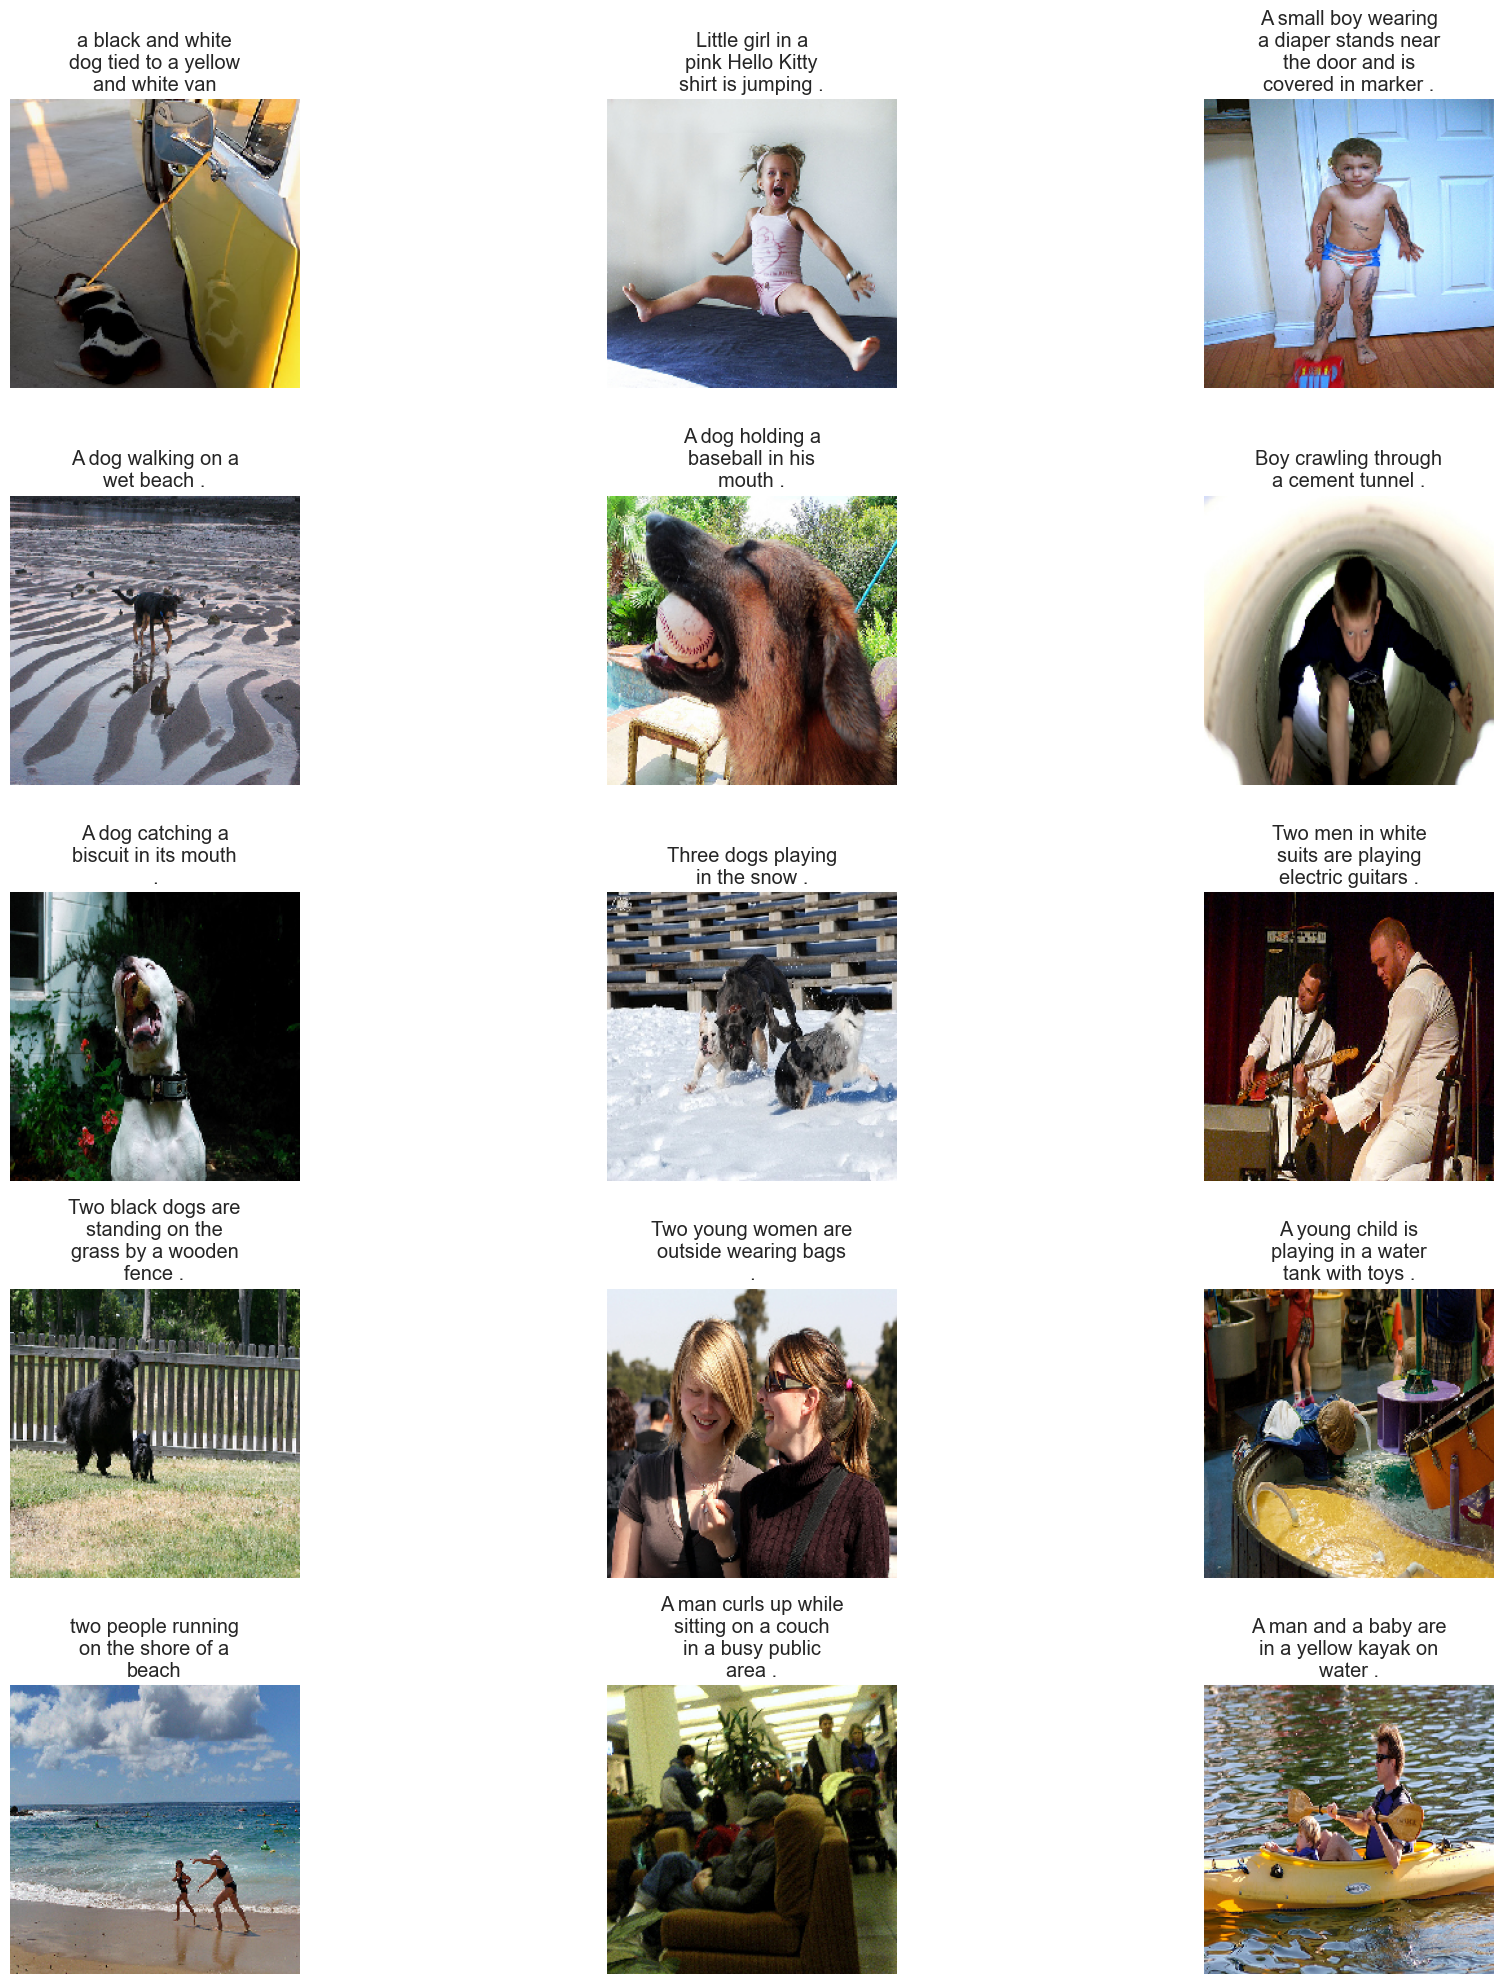

In [20]:
display_images(data.sample(15))

In [21]:
def text_preprocessing(data):
    data['caption'] = data['caption'].apply(lambda x: x.lower())
    data['caption'] = data['caption'].apply(lambda x: x.replace("[^A-Za-z]",""))
    data['caption'] = data['caption'].apply(lambda x: x.replace("\s+"," "))
    data['caption'] = data['caption'].apply(lambda x: " ".join([word for word in x.split() if len(word)>1]))
    data['caption'] = "startseq "+data['caption']+" endseq"
    return data

In [22]:
data = text_preprocessing(data)
captions = data['caption'].tolist()
captions[:10]

['startseq child in pink dress is climbing up set of stairs in an entry way endseq',
 'startseq girl going into wooden building endseq',
 'startseq little girl climbing into wooden playhouse endseq',
 'startseq little girl climbing the stairs to her playhouse endseq',
 'startseq little girl in pink dress going into wooden cabin endseq',
 'startseq black dog and spotted dog are fighting endseq',
 'startseq black dog and tri-colored dog playing with each other on the road endseq',
 'startseq black dog and white dog with brown spots are staring at each other in the street endseq',
 'startseq two dogs of different breeds looking at each other on the road endseq',
 'startseq two dogs on pavement moving toward each other endseq']

In [28]:
images = data['image'].unique().tolist()
images = len(images)
images

8091

In [25]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(captions)
vocab_size = len(tokenizer.word_index) + 1
max_length = max(len(caption.split()) for caption in captions)
print(max_length)


split_index = round(0.85*nimages)
train_images = images[:split_index]
val_images = images[split_index:]

train = data[data['image'].isin(train_images)]
test = data[data['image'].isin(val_images)]

train.reset_index(inplace=True,drop=True)
test.reset_index(inplace=True,drop=True)

tokenizer.texts_to_sequences([captions[1]])[0]

34


[1, 18, 315, 63, 195, 116, 2]

In [29]:
model = DenseNet201()
fe = Model(inputs=model.input, outputs=model.layers[-2].output)

img_size = 224
features = {}
for image in tqdm(data['image'].unique().tolist()):
    img = load_img(os.path.join(image_path,image),target_size=(img_size,img_size))
    img = img_to_array(img)
    img = img/255.
    img = np.expand_dims(img,axis=0)
    feature = fe.predict(img, verbose=0)
    features[image] = feature

82524592/82524592 ━━━━━━━━━━━━━━━━━━━━ 28s 0us/step


100%|██████████| 8091/8091 [1:04:53<00:00,  2.08it/s]    


In [30]:
class CustomDataGenerator(Sequence):
    
    def __init__(self, df, X_col, y_col, batch_size, directory, tokenizer, 
                 vocab_size, max_length, features,shuffle=True):
    
        self.df = df.copy()
        self.X_col = X_col
        self.y_col = y_col
        self.directory = directory
        self.batch_size = batch_size
        self.tokenizer = tokenizer
        self.vocab_size = vocab_size
        self.max_length = max_length
        self.features = features
        self.shuffle = shuffle
        self.n = len(self.df)
        
    def on_epoch_end(self):
        if self.shuffle:
            self.df = self.df.sample(frac=1).reset_index(drop=True)
    
    def __len__(self):
        return self.n // self.batch_size
    
    def __getitem__(self,index):
    
        batch = self.df.iloc[index * self.batch_size:(index + 1) * self.batch_size,:]
        X1, X2, y = self.__get_data(batch)        
        return (X1, X2), y
    
    def __get_data(self,batch):
        
        X1, X2, y = list(), list(), list()
        
        images = batch[self.X_col].tolist()
           
        for image in images:
            feature = self.features[image][0]
            
            captions = batch.loc[batch[self.X_col]==image, self.y_col].tolist()
            for caption in captions:
                seq = self.tokenizer.texts_to_sequences([caption])[0]

                for i in range(1,len(seq)):
                    in_seq, out_seq = seq[:i], seq[i]
                    in_seq = pad_sequences([in_seq], maxlen=self.max_length)[0]
                    out_seq = to_categorical([out_seq], num_classes=self.vocab_size)[0]
                    X1.append(feature)
                    X2.append(in_seq)
                    y.append(out_seq)
            
        X1, X2, y = np.array(X1), np.array(X2), np.array(y)
                
        return X1, X2, y


train_generator = CustomDataGenerator(df=train,X_col='image',y_col='caption',batch_size=64,directory=image_path,
                                      tokenizer=tokenizer,vocab_size=vocab_size,max_length=max_length,features=features)

validation_generator = CustomDataGenerator(df=test,X_col='image',y_col='caption',batch_size=64,directory=image_path,
                                      tokenizer=tokenizer,vocab_size=vocab_size,max_length=max_length,features=features)

In [31]:
train_generator[0]

((array([[7.8687946e-05, 7.3524076e-04, 1.1395995e-03, ..., 5.6523436e-01,
          2.2903755e-01, 6.9639885e-01],
         [7.8687946e-05, 7.3524076e-04, 1.1395995e-03, ..., 5.6523436e-01,
          2.2903755e-01, 6.9639885e-01],
         [7.8687946e-05, 7.3524076e-04, 1.1395995e-03, ..., 5.6523436e-01,
          2.2903755e-01, 6.9639885e-01],
         ...,
         [1.9476049e-04, 7.0213014e-04, 1.4947483e-03, ..., 2.7233697e-02,
          5.5759436e-01, 3.8916597e-01],
         [1.9476049e-04, 7.0213014e-04, 1.4947483e-03, ..., 2.7233697e-02,
          5.5759436e-01, 3.8916597e-01],
         [1.9476049e-04, 7.0213014e-04, 1.4947483e-03, ..., 2.7233697e-02,
          5.5759436e-01, 3.8916597e-01]], dtype=float32),
  array([[  0,   0,   0, ...,   0,   0,   1],
         [  0,   0,   0, ...,   0,   1,  42],
         [  0,   0,   0, ...,   1,  42,   3],
         ...,
         [  0,   0,   0, ...,  10,  76,  49],
         [  0,   0,   0, ...,  76,  49,   4],
         [  0,   0,   0, ...,

In [32]:
from tensorflow.keras.utils import plot_model

input1 = Input(shape=(1920,))
input2 = Input(shape=(max_length,))

img_features = Dense(256, activation='relu')(input1)
img_features_reshaped = Reshape((1, 256), input_shape=(256,))(img_features)

sentence_features = Embedding(vocab_size, 256, mask_zero=False)(input2)
merged = concatenate([img_features_reshaped,sentence_features],axis=1)
sentence_features = LSTM(256)(merged)
x = Dropout(0.5)(sentence_features)
x = add([x, img_features])
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(vocab_size, activation='softmax')(x)

caption_model = Model(inputs=[input1,input2], outputs=output)
caption_model.compile(loss='categorical_crossentropy',optimizer='adam')


from tensorflow.keras.callbacks import ModelCheckpoint

# Define the model checkpoint
model_name = "model.keras"  # Update the extension to .keras
checkpoint = ModelCheckpoint(
    model_name,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

earlystopping = EarlyStopping(monitor='val_loss',min_delta = 0, patience = 5, verbose = 1, restore_best_weights=True)

learning_rate_reduction = ReduceLROnPlateau(monitor='val_loss', 
                                            patience=3, 
                                            verbose=1, 
                                            factor=0.2, 
                                            min_lr=0.00000001)

history = caption_model.fit(
        train_generator,
        epochs=50,
        validation_data=validation_generator,
        callbacks=[checkpoint,earlystopping,learning_rate_reduction])

Epoch 1/50
537/537 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step - loss: 5.0871
Epoch 1: val_loss improved from None to 4.29171, saving model to model.keras

Epoch 1: finished saving model to model.keras
537/537 ━━━━━━━━━━━━━━━━━━━━ 198s 365ms/step - loss: 5.0871 - val_loss: 4.2917 - learning_rate: 0.0010
Epoch 2/50
537/537 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - loss: 4.2707
Epoch 2: val_loss improved from 4.29171 to 3.96680, saving model to model.keras

Epoch 2: finished saving model to model.keras
537/537 ━━━━━━━━━━━━━━━━━━━━ 170s 317ms/step - loss: 4.2707 - val_loss: 3.9668 - learning_rate: 0.0010
Epoch 3/50
537/537 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - loss: 3.9955
Epoch 3: val_loss improved from 3.96680 to 3.81205, saving model to model.keras

Epoch 3: finished saving model to model.keras
537/537 ━━━━━━━━━━━━━━━━━━━━ 169s 315ms/step - loss: 3.9955 - val_loss: 3.8121 - learning_rate: 0.0010
Epoch 4/50
537/537 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - loss: 3.8207
Epoch 4: val_loss improved from 3.812

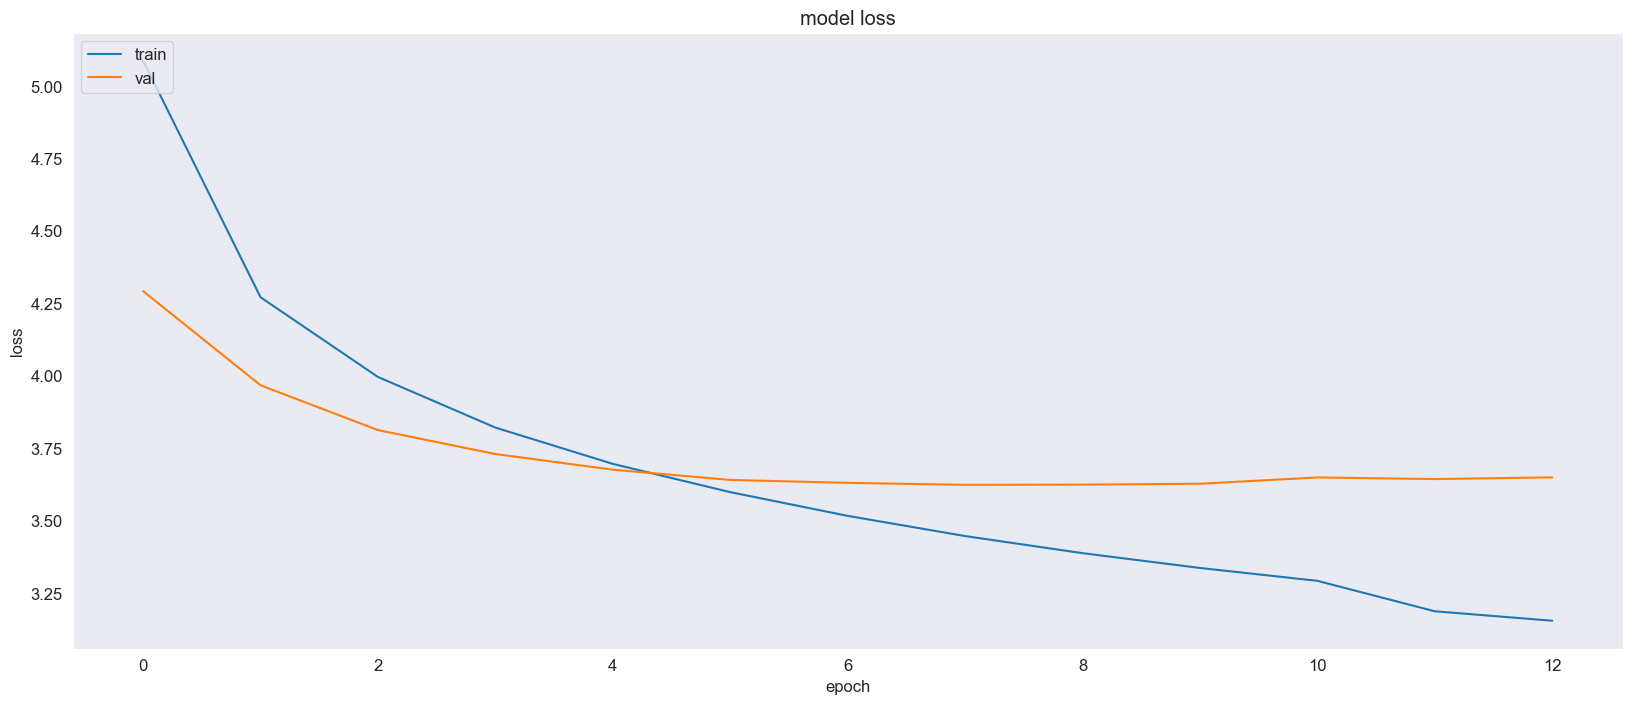

In [33]:
plt.figure(figsize=(20,8))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [35]:
import pickle

pickle.dump(tokenizer, open("tokenizer.pkl", "wb"))
pickle.dump(fe, open("feature_extractor.pkl", "wb"))

In [47]:

import os
import numpy as np
import pickle
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Project paths
BASE_DIR = os.getcwd()

model_path = os.path.join(BASE_DIR, "model.keras")
tokenizer_path = os.path.join(BASE_DIR, "tokenizer.pkl")
feature_extractor_path = os.path.join(BASE_DIR, "feature_extractor.pkl")


def generate_and_display_caption(
    image_path,
    model_path,
    tokenizer_path,
    feature_extractor_path,
    max_length=34,
    img_size=224
):

    # Check file existence
    for path in [image_path, model_path, tokenizer_path, feature_extractor_path]:
        if not os.path.exists(path):
            raise FileNotFoundError(f"File not found: {path}")

    # Load caption generation model
    caption_model = load_model(model_path)

    # Load feature extractor using Pickle
    with open(feature_extractor_path, "rb") as f:
        feature_extractor = pickle.load(f)

    # Load tokenizer
    with open(tokenizer_path, "rb") as f:
        tokenizer = pickle.load(f)

    # Preprocess image
    img = load_img(
        image_path,
        target_size=(img_size, img_size),
        color_mode="rgb"
    )

    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Extract image features
    image_features = feature_extractor.predict(
        img_array,
        verbose=0
    )

    # Generate caption
    in_text = "startseq"

    for i in range(max_length):

        sequence = tokenizer.texts_to_sequences([in_text])[0]

        sequence = pad_sequences(
            [sequence],
            maxlen=max_length
        )

        yhat = caption_model.predict(
            [image_features, sequence],
            verbose=0
        )

        yhat_index = np.argmax(yhat)

        word = tokenizer.index_word.get(yhat_index)

        if word is None:
            break

        if word == "endseq":
            break

        in_text += " " + word

    caption = in_text.replace("startseq", "").strip()

    # Display image and caption
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title(caption, fontsize=16, color="blue")
    plt.show()

    return caption


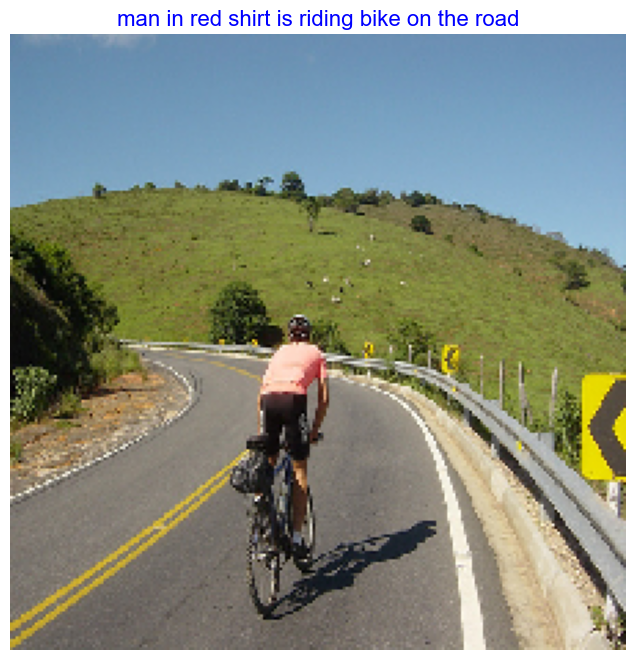

'man in red shirt is riding bike on the road'

In [49]:
image_path = r"C:\Users\arghy\Downloads\Images (2)\110595925_f3395c8bd6.jpg"

generate_and_display_caption(
    image_path,
    model_path,
    tokenizer_path,
    feature_extractor_path
)